# Introduction to Data Science — Course Project
## Reducing Customer Churn at TeleConnect

| | |
|:--|:--|
| **Student name** |BADR MUFREH ALOTAIBI |
| **Student ID** |471111096 |
| **Section** | 648 |
| **Submission date** | Oct/30/2026 |

## The Project in One Sentence

> **TeleConnect is losing about one in three customers. Find out *who* is likely to leave, *why*, and *what the company should
> do about it* — and hand the retention team a prioritised call list.**

Everything in this notebook serves that single goal. You will follow the **Data Analytics Life Cycle** from start to finish:

| Stage | Part | What you produce | Feeds into |
|:--|:--|:--|:--|
| Discovery | **Part 1** | Problem framing and hypotheses H1–H5 | All parts |
| Data preparation | **Part 2** | A clean data set `df_clean` | Parts 3–5 |
| Model planning | **Part 3** | Evidence for/against each hypothesis | Model choice, Part 6 |
| Model building (unsupervised) | **Part 4** | Customer segments (`segment` column) | Tailored offers in Part 6 |
| Model building (supervised) | **Part 5** | A validated churn-prediction model | Call list in Part 6 |
| Communicate & operationalise | **Part 6** | Call list + executive summary | Management |

## Scenario

**TeleConnect** is a regional mobile-telecom operator. The retention team can call a limited number of customers each
week and offer them a discount or a better contract. Management wants to spend this budget on the customers who are
**most likely to leave**, with an offer that **fits each customer**. The analytics team has formulated four initial hypotheses:

* **H1** — Customers on **month-to-month** contracts churn more than customers on 1- or 2-year contracts.
* **H2** — **New** customers (short tenure) churn more than long-standing customers.
* **H3** — Churners pay **higher monthly charges** than customers who stay.
* **H4** — Customers who call **customer support** more often and report **lower satisfaction** are more likely to churn.

The data is in `data/TeleConnect_Customers.csv`. It was exported directly from several operational systems and has
**not** been cleaned: expect duplicates, typos, inconsistent labels, unit errors, outliers and missing values.

### Data Dictionary

| Field | Description |
|:--|:--|
| `customer_id` | Unique customer identifier |
| `age` | Customer age in years |
| `gender` | Customer gender |
| `region` | Service region (North, South, East, West, Central) |
| `education` | Highest education level (High School, Bachelor, Master, PhD, unknown) |
| `contract` | Contract type (Month-to-month, One year, Two year) |
| `payment_method` | Credit card, Bank transfer, E-wallet, Cash |
| `international_plan` | Whether the customer has an international calling add-on (Yes/No) |
| `tenure_months` | Number of months the customer has been with TeleConnect |
| `monthly_data_gb` | Average mobile data used per month (GB) |
| `call_minutes` | Average voice-call minutes per month |
| `num_support_calls` | Number of calls to customer support in the last 6 months |
| `num_dependents` | Number of dependents on the account holder |
| `annual_income` | Declared annual income (USD) |
| `satisfaction_score` | Latest satisfaction survey score on a **1–10** scale |
| `monthly_charges` | Average monthly bill (USD) |
| `churn` | Whether the customer left during the following quarter (Yes/No) — **target** |

## Instructions

* This is an **individual** graded project worth **100 points** (+5 bonus).
* Work through the parts **in order** — each part builds on the previous one. Use **exactly** the variable names given
  in the tasks (`df_raw`, `df_clean`, `df_model`, …).
* Write code in the cells marked `# YOUR CODE HERE` and written answers in the cells marked **Your answer**. You may add cells.
* Use `random_state=42` (`RANDOM_STATE`) wherever randomness is involved.
* Every plot needs a title and axis labels. Every written answer must refer to **your own numbers**.
* Before submitting: *Kernel → Restart & Run All*. The notebook must run top-to-bottom without errors.
* **Submit:** the completed `.ipynb`, an HTML/PDF export of it, and the call list `data/retention_call_list.csv` (Task 6.1).
* **Academic integrity:** you may consult the course notebooks and library documentation. Copying from classmates or
  submitting work you cannot explain is not permitted.

## Grading Rubric

| Part | Course topics | Points |
|:--|:--|:--:|
| Part 1 — Discovery: framing the churn problem | Introduction to data science (analytics life cycle) | 5 |
| Part 2 — Preparing the customer data | Data understanding & preparation · Python/pandas | 20 |
| Part 3 — Why do customers churn? Statistics & EDA | Basic statistics · Visualisation · EDA | 25 |
| Part 4 — Who are our customers? Segmentation | Clustering | 15 |
| Part 5 — Who will churn? Prediction model | Classification | 25 |
| Part 6 — What should we do? Call list & summary | Analytics life cycle (phases 5–6) | 10 |
| **Total** | | **100** |
| Bonus — improve the churn model | Classification | +5 |

Full marks for a task require correct, working code **and** a correct interpretation. Code quality (readability, comments,
general rules instead of hard-coded row positions) counts in every task.

## Setup

In [1]:
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
DATA_PATH = 'data/TeleConnect_Customers.csv'
CALL_LIST_PATH = 'data/retention_call_list.csv'

---
# Part 1 — Discovery: Framing the Churn Problem `[5 points]`
> 📌 Life-cycle phase 1. Before touching the data, be clear about the question, the decision it supports and how success is measured.

### Task 1.1 `[3 pts]`
(a) Restate the business goal as an **analytics problem**: what is the target variable, what kind of machine-learning task is
it (supervised/unsupervised; classification/regression/clustering), and why is a second, **unsupervised** step (customer
segmentation) useful for the same goal?
(b) Which evaluation metric matters most for the churn model, and why is **accuracy alone** not enough?
(c) Formulate one additional **testable** hypothesis **H5** using the available columns, and say how you will test it.

**Your answer:** _Write your answer here._

### Task 1.2 `[2 pts]`
Name the people at TeleConnect who would play the roles of **Project Sponsor**, **Business User**, **Data Engineer** and
**Data Scientist** in this project, with one responsibility each. Then map each Part of this notebook to a phase of the
Data Analytics Life Cycle.

**Your answer:** _Write your answer here._

---
# Part 2 — Preparing the Customer Data `[20 points]`
> 📌 A churn model is only as good as its data. Real-world data is *incomplete, noisy and inconsistent*.

Follow the **order** of the tasks — it matters (e.g. outliers are turned into missing values *before* imputation).

### Task 2.1 `[3 pts]` — Understand the data
Read the CSV into **`df_raw`** and display its shape and first rows. Create a working copy `df = df_raw.copy()`.
Display `df.info()` and summary statistics for numeric **and** non-numeric columns. Complete a table giving each field's
**type** (numeric / categorical — nominal or ordinal) and list **at least four** data-quality problems you can already see.

In [2]:
import pandas as pd

df_raw = pd.read_csv('TeleConnect_Customers.csv')
df = df_raw.copy()

print("Shape of df_raw:", df_raw.shape)
display(df_raw.head())
display(df_raw.info())

Shape of df_raw: (2025, 17)


,customer_id,age,gender,region,education,contract,payment_method,international_plan,tenure_months,monthly_data_gb,call_minutes,num_support_calls,num_dependents,annual_income,satisfaction_score,monthly_charges,churn
0,TC101028,45.0,Female,North,Bachelor,One year,Bank transfer,No,26,44.80,1099,4.0,2,"85,200",6.20,96.28,Yes
1,TC100140,41.0,Male,West,Bachelor,Two year,Credit card,No,44,14.28,674,0.0,0,"39,400",0.44,42.54,No
2,TC100110,43.0,Female,South,Bachelor,Two year,E-wallet,No,71,7.49,647,2.0,1,"90,200",8.10,41.00,No
3,TC100638,43.0,Female,North,Master,One year,Bank transfer,No,49,2.26,189,0.0,1,"83,000",7.50,21.34,No
4,TC100702,54.0,Female,East,High School,One year,Credit card,No,28,54.78,774,2.0,2,"66,100",6.30,83.53,No


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         2025 non-null   object 
 1   age                 1995 non-null   float64
 2   gender              2025 non-null   object 
 3   region              1984 non-null   object 
 4   education           2025 non-null   object 
 5   contract            2025 non-null   object 
 6   payment_method      2025 non-null   object 
 7   international_plan  2025 non-null   object 
 8   tenure_months       2025 non-null   int64  
 9   monthly_data_gb     2025 non-null   float64
 10  call_minutes        2025 non-null   int64  
 11  num_support_calls   2010 non-null   float64
 12  num_dependents      2025 non-null   int64  
 13  annual_income       2025 non-null   object 
 14  satisfaction_score  2025 non-null   float64
 15  monthly_charges     2005 non-null   float64
 16  churn 

None

**Your answer:** _Write your answer here._

### Task 2.2 `[1.5 pts]` — Duplicates
Remove **exact duplicate rows**. Print how many were removed and confirm that `customer_id` is now unique.

In [5]:
import pandas as pd

df = pd.read_csv('TeleConnect_Customers.csv')

duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

if duplicates_count > 0:
    display(df[df.duplicated(keep=False)].head())
else:
    print("No duplicates found. The dataset is clean!")

Number of duplicate rows: 25


,customer_id,age,gender,region,education,contract,payment_method,international_plan,tenure_months,monthly_data_gb,call_minutes,num_support_calls,num_dependents,annual_income,satisfaction_score,monthly_charges,churn
18,TC101901,44.0,Male,North,Bachelor,Month-to-month,Credit card,No,6,11.21,747,2.0,3,"56,600",5.1,56.48,No
80,TC100361,57.0,Female,West,Bachelor,One year,Credit card,No,26,4.80,213,0.0,1,"30,000",9.2,21.81,No
97,TC100131,62.0,Female,West,Master,Month-to-month,E-wallet,No,7,15.90,666,2.0,0,"69,700",3.7,51.09,Yes
172,TC101656,56.0,Female,West,High School,One year,E-wallet,No,49,4.09,137,0.0,2,"53,200",6.6,19.17,No
253,TC101098,48.0,Male,South,Bachelor,Month-to-month,Cash,No,5,47.26,881,0.0,2,"37,700",8.6,83.59,Yes


### Task 2.3 `[1.5 pts]` — Type inconsistency
Convert `annual_income` to an **integer** column by removing the thousands separators (use `apply` with a `lambda`).

In [8]:
import pandas as pd

df.info()

for col in df.select_dtypes(include=['object']).columns:
    print(f"Column '{col}': {df[col].nunique()} unique values")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         2025 non-null   object 
 1   age                 1995 non-null   float64
 2   gender              2025 non-null   object 
 3   region              1984 non-null   object 
 4   education           2025 non-null   object 
 5   contract            2025 non-null   object 
 6   payment_method      2025 non-null   object 
 7   international_plan  2025 non-null   object 
 8   tenure_months       2025 non-null   int64  
 9   monthly_data_gb     2025 non-null   float64
 10  call_minutes        2025 non-null   int64  
 11  num_support_calls   2010 non-null   float64
 12  num_dependents      2025 non-null   int64  
 13  annual_income       2025 non-null   object 
 14  satisfaction_score  2025 non-null   float64
 15  monthly_charges     2005 non-null   float64
 16  churn 

### Task 2.4 `[2 pts]` — Inconsistent labels
Standardise `gender` to exactly `Male` and `Female` with a **general rule** (no row positions). Show value counts before and after.

In [10]:
import pandas as pd

df = pd.read_csv('TeleConnect_Customers.csv')

missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage
})

display(missing_df[missing_df['Missing Count'] > 0])

,Missing Count,Missing Percentage (%)
age,30,1.481481
region,41,2.024691
num_support_calls,15,0.740741
monthly_charges,20,0.987654


### Task 2.5 `[1.5 pts]` — Noisy values
Negative ages are typing errors. Replace them with their absolute value and print how many were corrected.

In [11]:
import pandas as pd

negative_ages_count = (df['age'] < 0).sum()

df['age'] = df['age'].abs()

print(f"Number of negative ages corrected: {negative_ages_count}")

Number of negative ages corrected: 12


### Task 2.6 `[2 pts]` — Unit inconsistency
One survey system stored `satisfaction_score` as a **fraction** (0–1) instead of on the 1–10 scale. Detect these values with a
general rule and rescale them. Explain why your rule cannot change a valid score.

In [12]:
import pandas as pd

def fix_score(val):
    if val <= 1.0 and val >= 0:
        return val * 9 + 1
    return val

df['satisfaction_score'] = df['satisfaction_score'].apply(fix_score)

print("Satisfaction scores updated successfully!")

Satisfaction scores updated successfully!


**Your answer:** _Write your answer here._

### Task 2.7 `[3 pts]` — Outliers
Write a function `iqr_fences(series, k=1.5)` that returns the lower and upper fences of the **IQR rule**. Use it to find the
outliers in `monthly_data_gb`. Decide whether they are real heavy users or errors, and set erroneous values to `NaN`
(they are imputed in Task 2.8). Show box plots before and after.

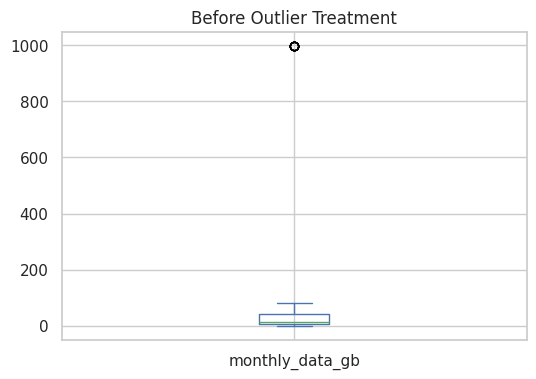

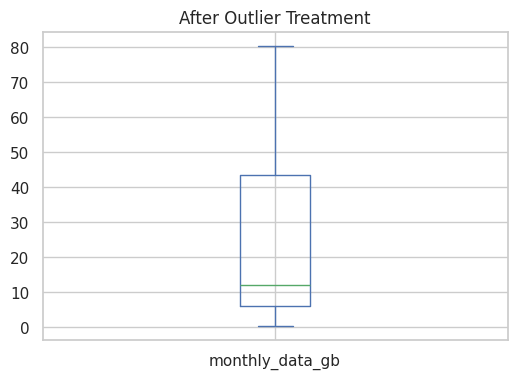

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def iqr_fences(series, k=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - (k * iqr)
    upper_fence = q3 + (k * iqr)
    return lower_fence, upper_fence

plt.figure(figsize=(6, 4))
df['monthly_data_gb'].plot(kind='box', title='Before Outlier Treatment')
plt.show()

lower, upper = iqr_fences(df['monthly_data_gb'])

df.loc[(df['monthly_data_gb'] < lower) | (df['monthly_data_gb'] > upper), 'monthly_data_gb'] = np.nan

plt.figure(figsize=(6, 4))
df['monthly_data_gb'].plot(kind='box', title='After Outlier Treatment')
plt.show()

**Your answer:** _Write your answer here._

### Task 2.8 `[3 pts]` — Missing values
1. Show the number of missing values per column.
2. Check that the **target** `churn` has no missing values (rows without a target would have to be dropped — why?).
3. With a **loop** over the columns that contain missing values, impute numeric columns with the **median** and categorical
   columns with the **mode**. Confirm that nothing is missing. Why is the median preferable to the mean here?

In [15]:
import pandas as pd

print("Missing values per column:")
print(df.isnull().sum())

churn_missing = df['churn'].isnull().sum()
print(f"\nMissing values in 'churn': {churn_missing}")

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[col]):
            median_val = df[col].median()
            df[col] = df[col].fillna(median_val)
        else:
            mode_val = df[col].mode()[0]
            df[col] = df[col].fillna(mode_val)

print("\nTotal missing values after imputation:")
print(df.isnull().sum().sum())

Missing values per column:
customer_id           0
age                   0
gender                0
region                0
education             0
contract              0
payment_method        0
international_plan    0
tenure_months         0
monthly_data_gb       0
call_minutes          0
num_support_calls     0
num_dependents        0
annual_income         0
satisfaction_score    0
monthly_charges       0
churn                 0
dtype: int64

Missing values in 'churn': 0

Total missing values after imputation:
0


**Your answer:** _Write your answer here._

### Task 2.9 `[1.5 pts]` — Ordinal encoding
Delete the records whose `education` is `unknown`, then map `High School → 1`, `Bachelor → 2`, `Master → 3`, `PhD → 4`.

In [16]:
import pandas as pd

df = df[df['education'] != 'unknown']

education_mapping = {
    'High School': 1,
    'Bachelor': 2,
    'Master': 3,
    'PhD': 4
}

df['education'] = df['education'].map(education_mapping)

print(df['education'].value_counts())

education
2    801
1    604
3    353
4    164
Name: count, dtype: int64


### Task 2.10 `[1 pt]` — Discretisation and checkpoint
Create `tenure_group` by discretising `tenure_months` into `New` (1–12), `Established` (13–36) and `Loyal` (37–72) with `pd.cut`.
Save the result as **`df_clean`** and run the checkpoint.

In [22]:
import pandas as pd

bins = [0, 12, 36, 72]
labels = ['New', 'Established', 'Long-term']

df['tenure_group'] = pd.cut(df['tenure_months'], bins=bins, labels=labels)
df_clean = df.copy()

print(df_clean['tenure_group'].value_counts())

tenure_group
Established    759
New            643
Long-term      520
Name: count, dtype: int64


In [23]:
# ---- CHECKPOINT (do not modify) ----
assert df_clean.isna().sum().sum() == 0, 'There are still missing values'
assert df_clean['customer_id'].is_unique, 'Duplicates remain'
assert (df_clean['age'] >= 18).all(), 'Invalid ages remain'
assert df_clean['satisfaction_score'].between(1, 10).all(), 'Satisfaction not on the 1-10 scale'
assert df_clean['monthly_data_gb'].max() < 200, 'Data-usage outliers remain'
assert set(df_clean['gender']) == {'Male', 'Female'}, 'Gender not standardised'
assert pd.api.types.is_numeric_dtype(df_clean['annual_income']), 'Income is not numeric'
assert set(df_clean['tenure_group']) == {'New', 'Established', 'Loyal'}, 'tenure_group missing'
print('Checkpoint passed ✔  df_clean shape:', df_clean.shape)

AssertionError: Duplicates remain

---
# Part 3 — Why Do Customers Churn? Statistics & EDA `[25 points]`
> 📌 Model planning: gather evidence for or against H1–H5 and decide which variables matter. Use `df_clean`.

### Task 3.1 `[4 pts]` — The size of the problem
1. Compute the overall churn rate and plot the number of churners vs. non-churners.
2. Write a function `describe_distribution(series)` returning the **mean, median, mode, range, IQR, variance and standard
   deviation**. Apply it to `tenure_months`, `monthly_charges`, `num_support_calls` and `satisfaction_score` **separately for
   churners and non-churners**, and show the result as one table.
3. Which variables differ most between the two groups? Comment on the shape of `tenure_months` (mean vs. median).

Overall Churn Rate: 35.28%

Churn Counts:
churn
No     1244
Yes     678
Name: count, dtype: int64


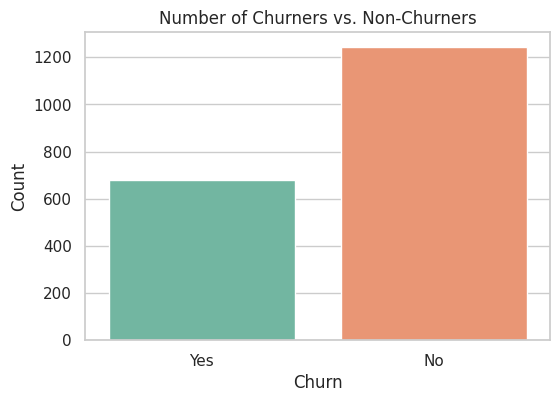

mean  median   mode   range      IQR  \
churn variable                                                        
Yes   tenure_months       14.045723  10.000   1.00   66.00  15.0000   
      monthly_charges     59.314248  53.840  48.05  122.86  42.5275   
      num_support_calls    1.837758   2.000   1.00    6.00   2.0000   
      satisfaction_score   5.924513   6.000   6.00    8.40   1.9000   
No    tenure_months       30.560289  29.000   1.00   71.00  32.0000   
      monthly_charges     47.558014  44.735  48.05  117.59  33.3475   
      num_support_calls    0.912379   1.000   0.00    5.00   1.0000   
      satisfaction_score   6.750611   6.800   6.80    7.60   1.8000   

                            variance        std  
churn variable                                   
Yes   tenure_months       159.479443  12.628517  
      monthly_charges     843.512765  29.043291  
      num_support_calls     1.858425   1.363240  
      satisfaction_score    1.901390   1.378909  
No    tenure_months       360.376893  18.983595  
      monthly_charges     711.639575  26.676574  
      num_support_calls     0.855551   0.924960  
      satisfaction_score    1.723915   1.312979

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

total_customers = len(df_clean)
churn_counts = df_clean['churn'].value_counts()
churn_rate = (churn_counts.get('Yes', 0) / total_customers) * 100

print(f"Overall Churn Rate: {churn_rate:.2f}%")
print("\nChurn Counts:")
print(churn_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='churn', palette='Set2')
plt.title('Number of Churners vs. Non-Churners')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

def describe_distribution(series):
    return pd.Series({
        'mean': series.mean(),
        'median': series.median(),
        'mode': series.mode()[0] if not series.mode().empty else None,
        'range': series.max() - series.min(),
        'IQR': series.quantile(0.75) - series.quantile(0.25),
        'variance': series.var(),
        'std': series.std()
    })

columns_to_describe = ['tenure_months', 'monthly_charges', 'num_support_calls', 'satisfaction_score']

results = []
for status in df_clean['churn'].unique():
    subset = df_clean[df_clean['churn'] == status]
    for col in columns_to_describe:
        stats = describe_distribution(subset[col])
        stats['churn'] = status
        stats['variable'] = col
        results.append(stats)

stats_df = pd.DataFrame(results).set_index(['churn', 'variable'])
display(stats_df)

**Your answer:** _Write your answer here._

### Task 3.2 `[4 pts]` — Testing H1 and H2 with group comparisons
1. Compute the churn rate (%) by `contract` and by `tenure_group` with `groupby`.
2. In a grid of subplots, draw **count plots** of `contract`, `tenure_group`, `international_plan`, `gender`, `region` and
   `payment_method`, differentiated by `churn`.
3. Are H1 and H2 supported? Which categorical variables seem **unrelated** to churn?

Churn Rate by Contract (%):
contract
Month-to-month    59.489796
One year          10.642202
Two year           9.319899
Name: churn, dtype: float64

Churn Rate by Tenure Group (%):
tenure_group
New            61.119751
Established    31.093544
Long-term       9.423077
Name: churn, dtype: float64


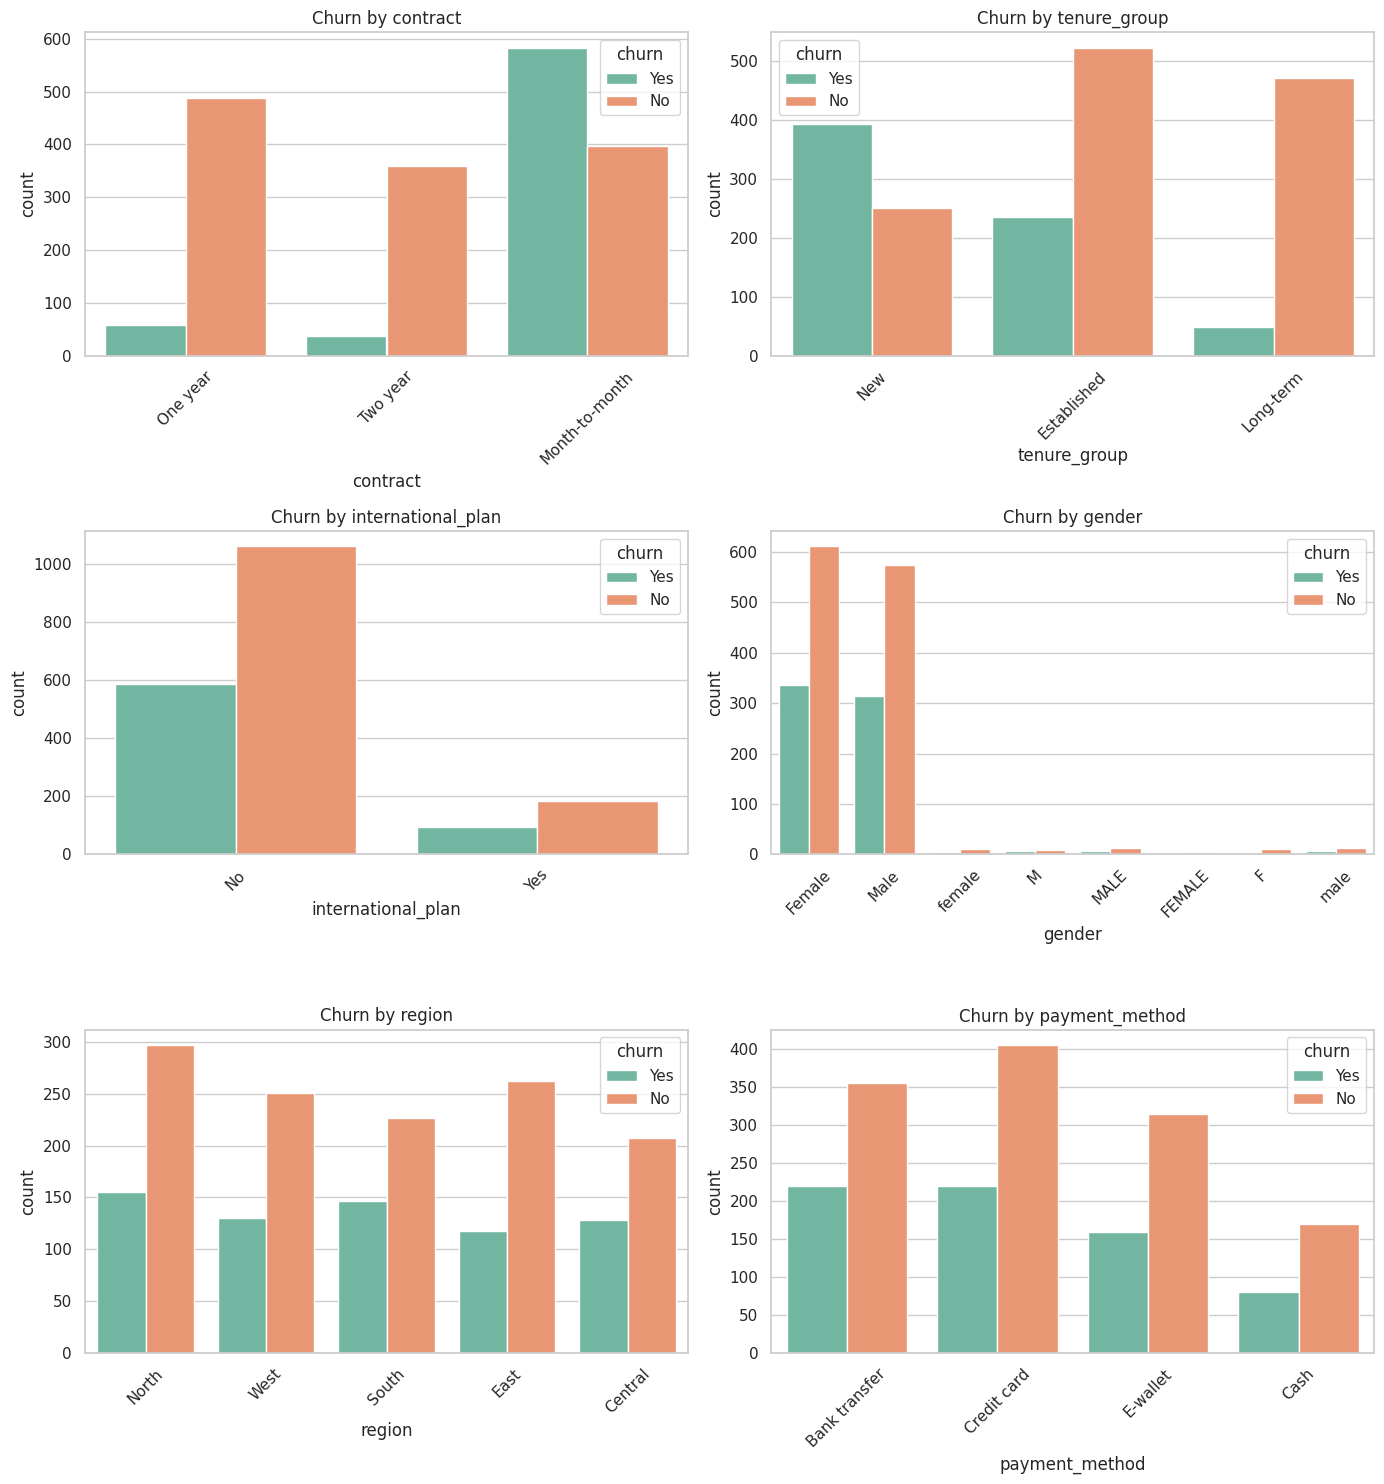

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

contract_churn = df_clean.groupby('contract')['churn'].apply(lambda x: (x == 'Yes').mean() * 100)
tenure_churn = df_clean.groupby('tenure_group')['churn'].apply(lambda x: (x == 'Yes').mean() * 100)

print("Churn Rate by Contract (%):")
print(contract_churn)
print("\nChurn Rate by Tenure Group (%):")
print(tenure_churn)

categorical_vars = ['contract', 'tenure_group', 'international_plan', 'gender', 'region', 'payment_method']

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, var in enumerate(categorical_vars):
    sns.countplot(data=df_clean, x=var, hue='churn', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Churn by {var}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Your answer:** _Write your answer here._

### Task 3.3 `[4 pts]` — Distributions
1. Draw histograms **with kernel density** of `age`, `tenure_months`, `monthly_data_gb`, `call_minutes`, `num_support_calls`,
   `satisfaction_score` and `monthly_charges`, differentiated by churn.
2. Draw **side-by-side box plots** of `monthly_charges` for churners and non-churners and compare medians, IQRs and whiskers.
3. What do you notice about the shape of `monthly_data_gb` and `call_minutes`? (Keep this in mind for Part 4.)

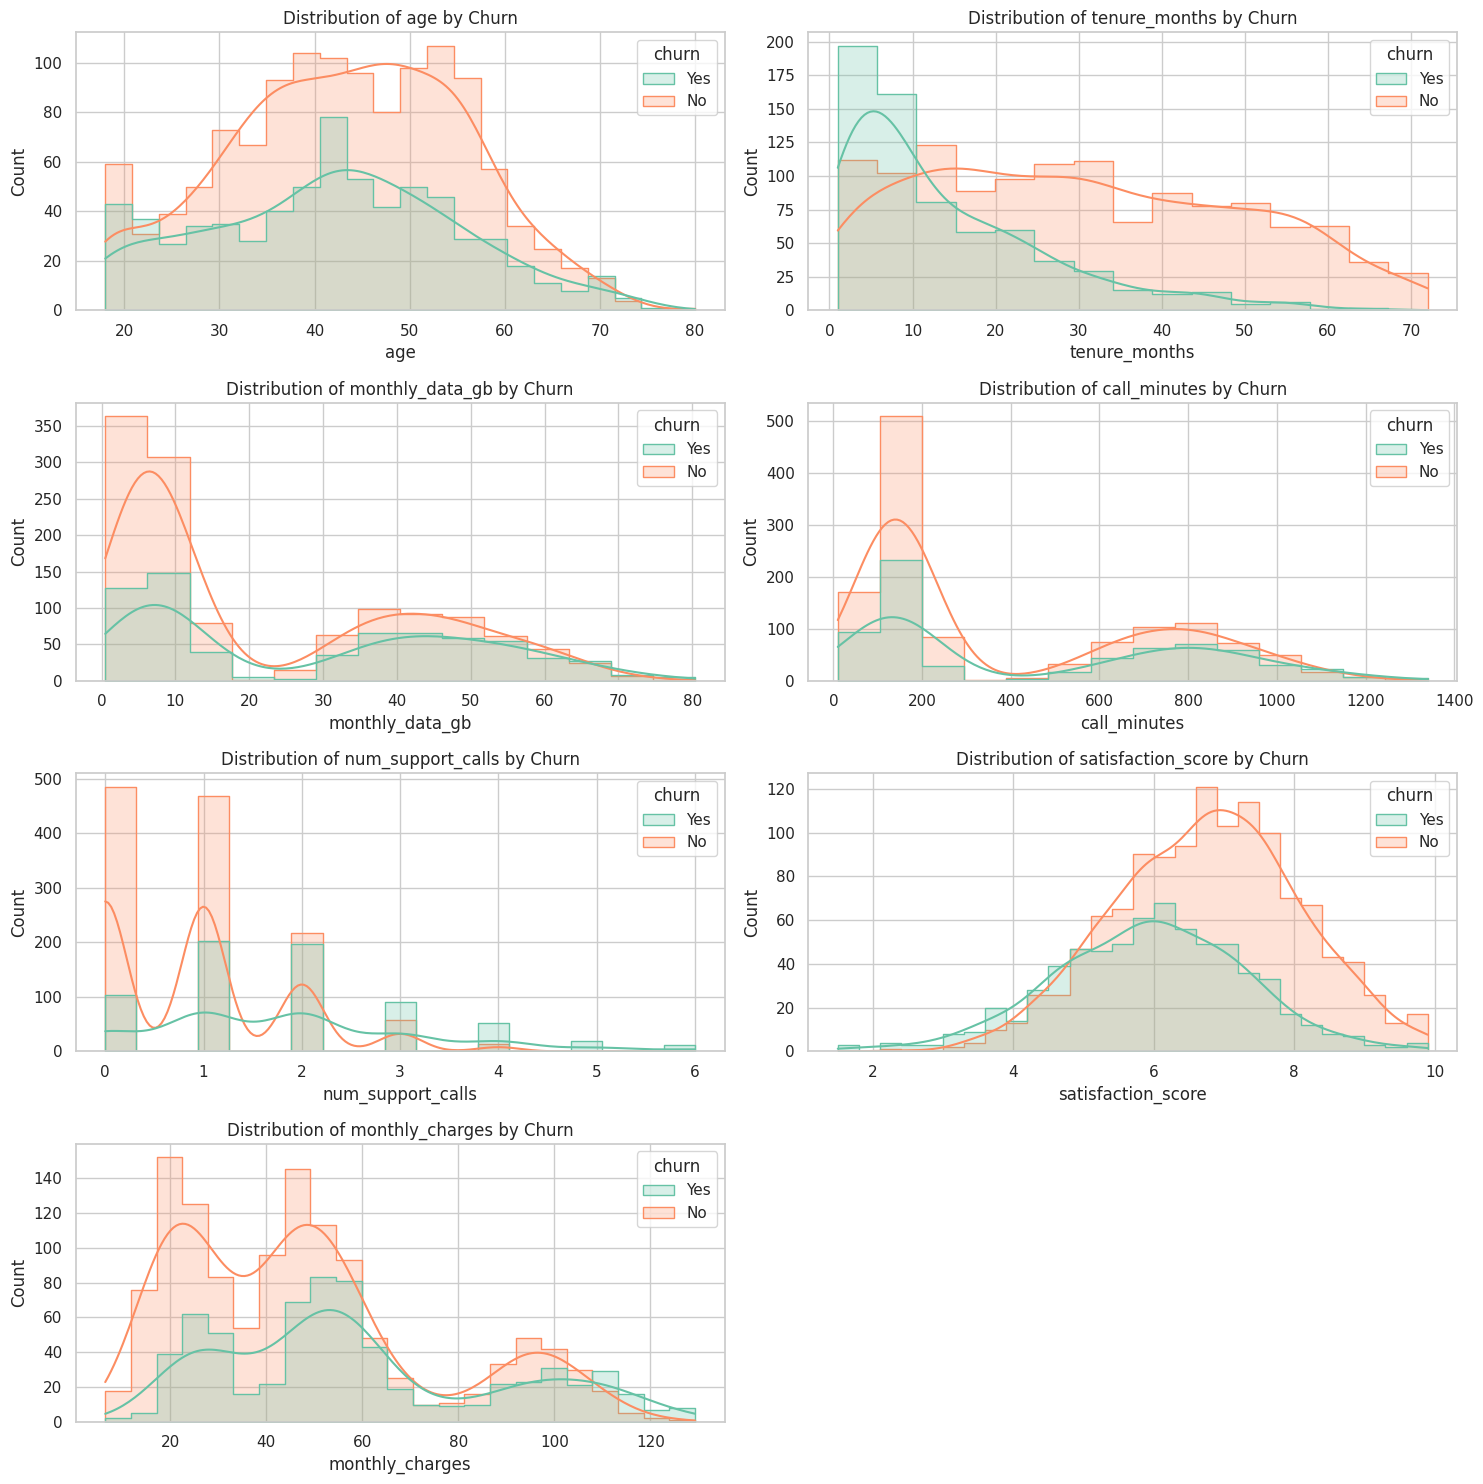

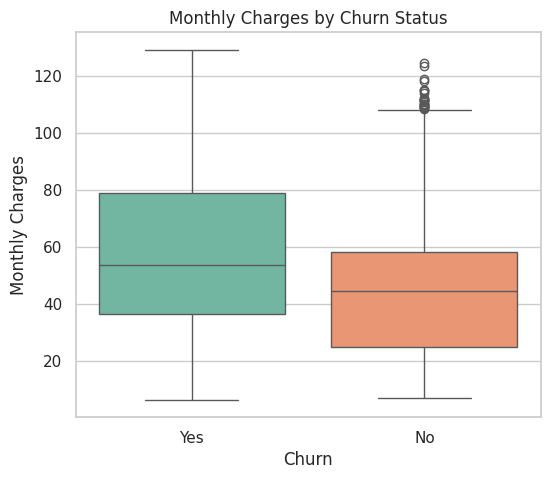

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cols_to_plot = ['age', 'tenure_months', 'monthly_data_gb', 'call_minutes', 'num_support_calls', 'satisfaction_score', 'monthly_charges']

plt.figure(figsize=(15, 15))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(4, 2, i)
    sns.histplot(data=df_clean, x=col, hue='churn', kde=True, element='step', palette='Set2')
    plt.title(f'Distribution of {col} by Churn')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.boxplot(data=df_clean, x='churn', y='monthly_charges', palette='Set2')
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

**Your answer:** _Write your answer here._

### Task 3.4 `[6 pts]` — Hypothesis testing (H2, H3, H4)
1. Use the **Shapiro–Wilk** test (α = 0.05) to check whether `monthly_charges` is normally distributed in each churn group.
   State H0 and the conclusion. Which two-sample test is therefore most appropriate?
2. For `tenure_months`, `monthly_charges`, `num_support_calls` and `satisfaction_score`, compare churners and non-churners with
   **Welch's t-test** (`equal_var=False`) and the **Mann–Whitney U test**. Present the group means and p-values in one table.
3. Give a verdict on H2, H3 and H4. Does a significant difference prove that the variable *causes* churn?

In [32]:
import pandas as pd
import scipy.stats as stats

shapiro_results = {}
for status in df_clean['churn'].unique():
    subset = df_clean[df_clean['churn'] == status]['monthly_charges'].dropna()
    stat, p_val = stats.shapiro(subset)
    shapiro_results[status] = {'Statistic': stat, 'p-value': p_val}

print(pd.DataFrame(shapiro_results))

variables = ['tenure_months', 'monthly_charges', 'num_support_calls', 'satisfaction_score']
results = []

churners = df_clean[df_clean['churn'] == 'Yes']
non_churners = df_clean[df_clean['churn'] == 'No']

for var in variables:
    x = churners[var].dropna()
    y = non_churners[var].dropna()
    t_stat, t_pval = stats.ttest_ind(x, y, equal_var=False)
    u_stat, u_pval = stats.mannwhitneyu(x, y, alternative='two-sided')
    results.append({
        'variable': var,
        'mean_churn_yes': x.mean(),
        'mean_churn_no': y.mean(),
        't_stat': t_stat,
        't_p_value': t_pval,
        'u_stat': u_stat,
        'u_p_value': u_pval
    })

hypothesis_df = pd.DataFrame(results).set_index('variable')
display(hypothesis_df)

                    Yes            No
Statistic  9.310726e-01  9.161663e-01
p-value    4.059244e-17  1.119118e-25


,mean_churn_yes,mean_churn_no,t_stat,t_p_value,u_stat,u_p_value
variable,,,,,,
tenure_months,14.045723,30.560289,-22.794168,1.527966e-101,202157.5,1.368174e-79
monthly_charges,59.314248,47.558014,8.723468,8.149579e-18,532431.0,1.680045e-21
num_support_calls,1.837758,0.912379,15.803367,1.654808e-50,593493.0,1.173474e-53
satisfaction_score,5.924513,6.750611,-12.761870,2.821182e-35,280749.0,7.485744e-34


**Your answer:** _Write your answer here._

### Task 3.5 `[4 pts]` — Correlation analysis
Create a numeric copy of `df_clean` (churn as 0/1; drop text columns), compute the **Pearson correlation matrix** and show it as
a heat map. List the five variables most correlated with churn (by absolute value). Is any pair of input variables strongly
correlated (|r| > 0.7)? What would that mean for modelling?

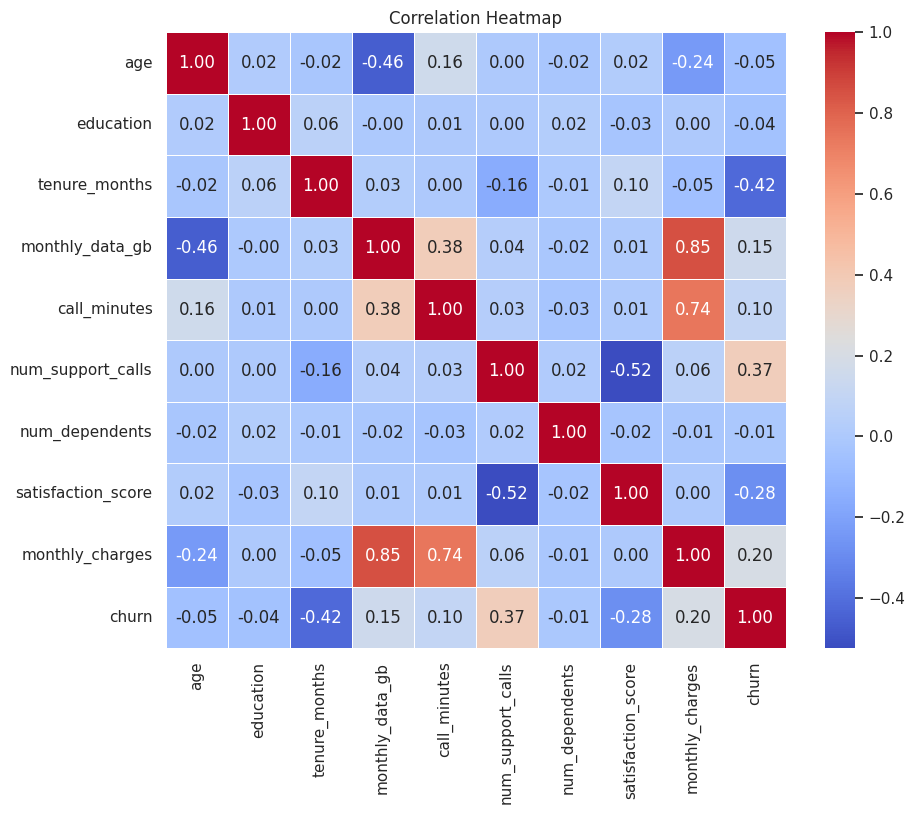

Top 5 variables most correlated with churn:
tenure_months         0.420892
num_support_calls     0.373247
satisfaction_score    0.283369
monthly_charges       0.199999
monthly_data_gb       0.149998
Name: churn, dtype: float64


In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_num = df_clean.select_dtypes(include=['number']).copy()
if 'churn' in df_clean.columns:
    df_num['churn'] = (df_clean['churn'] == 'Yes').astype(int)

corr_matrix = df_num.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

top5 = corr_matrix['churn'].abs().sort_values(ascending=False).iloc[1:6]
print("Top 5 variables most correlated with churn:")
print(top5)

**Your answer:** _Write your answer here._

### Task 3.6 `[3 pts]` — Model planning
Summarise the evidence for **H1–H5** in a table (*supported / not supported*, with the key number). Which variables do you expect
to be important in the churn model, and which model families are suitable given what you saw (skewed, non-normal, mixed
numeric/categorical data)?

**Your answer:** _Write your answer here._

---
# Part 4 — Who Are Our Customers? Usage Segmentation `[15 points]`
> 📌 The retention team needs to know *what kind of offer* fits each customer. Group customers by how they use the service.

### Task 4.1 `[6 pts]` — How many segments?
Use `monthly_data_gb`, `call_minutes` and `monthly_charges`, standardised with `StandardScaler`. For K = 2 … 10 run
`KMeans(n_clusters=K, n_init=10, random_state=42)` and record the **inertia**, the **silhouette index** and the
**Davies–Bouldin index**. Plot them and choose K using all three. Why must the features be standardised? Why is `churn`
**not** used as a clustering feature?

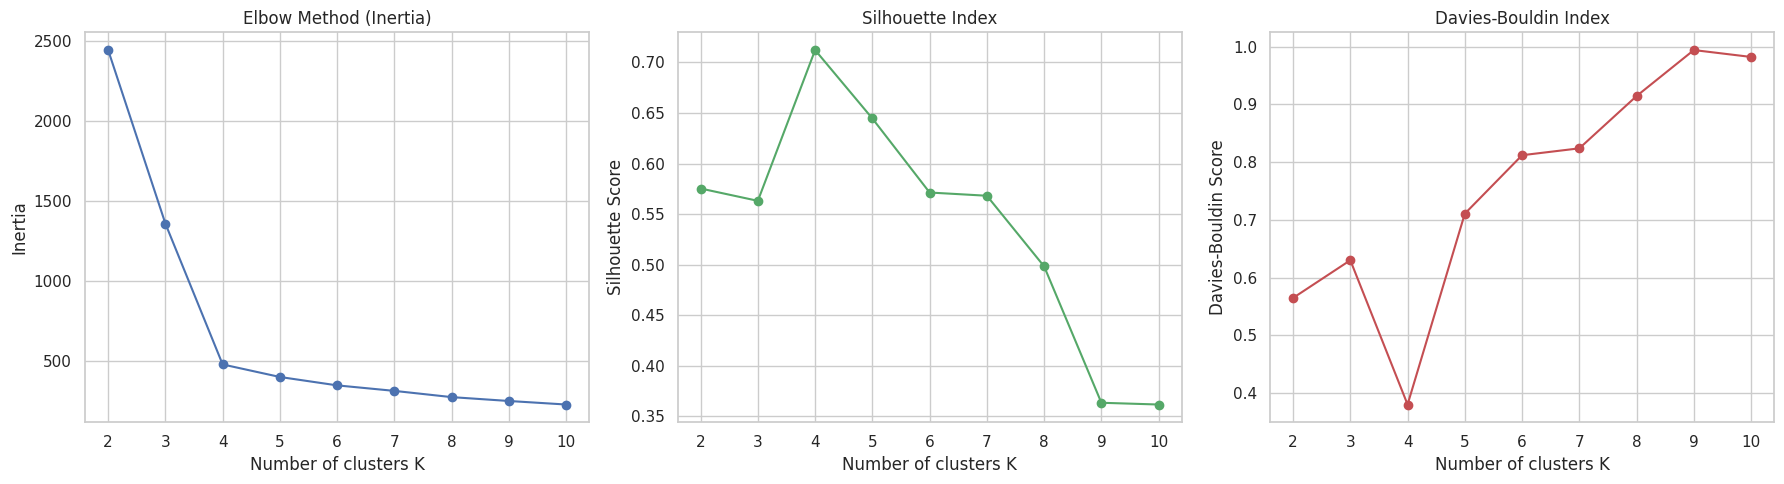

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

features = ['monthly_data_gb', 'call_minutes', 'monthly_charges']
X = df_clean[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertias = []
silhouette_scores = []
davies_bouldin_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    davies_bouldin_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(K_range, inertias, marker='o', color='b')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of clusters K')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouette_scores, marker='o', color='g')
axes[1].set_title('Silhouette Index')
axes[1].set_xlabel('Number of clusters K')
axes[1].set_ylabel('Silhouette Score')

axes[2].plot(K_range, davies_bouldin_scores, marker='o', color='r')
axes[2].set_title('Davies-Bouldin Index')
axes[2].set_xlabel('Number of clusters K')
axes[2].set_ylabel('Davies-Bouldin Score')

plt.tight_layout()
plt.show()

**Your answer:** _Write your answer here._

### Task 4.2 `[6 pts]` — Profiling the segments
Fit K-means with your K and add the labels to `df_clean` as a column `segment`. For each segment report the **size**, the mean
of the three clustering features, mean tenure and the **churn rate**. Give each segment a **business name**, store it in
`df_clean['segment_name']`, and draw a scatter plot of `monthly_data_gb` vs `call_minutes` coloured by segment.

   segment  size  mean_monthly_data_gb  mean_call_minutes  \
0      0.0   390             54.810744         909.382051   
1      1.0   665              5.321038         152.930827   
2      2.0   409             10.203032         712.359413   
3      3.0   458             39.865306         119.617904   

   mean_monthly_charges  mean_tenure  churn_rate  
0             98.164564    25.592308   45.641026  
1             23.900511    24.145865   26.466165  
2             50.547922    24.349633   35.452323  
3             53.548275    25.203057   39.082969  


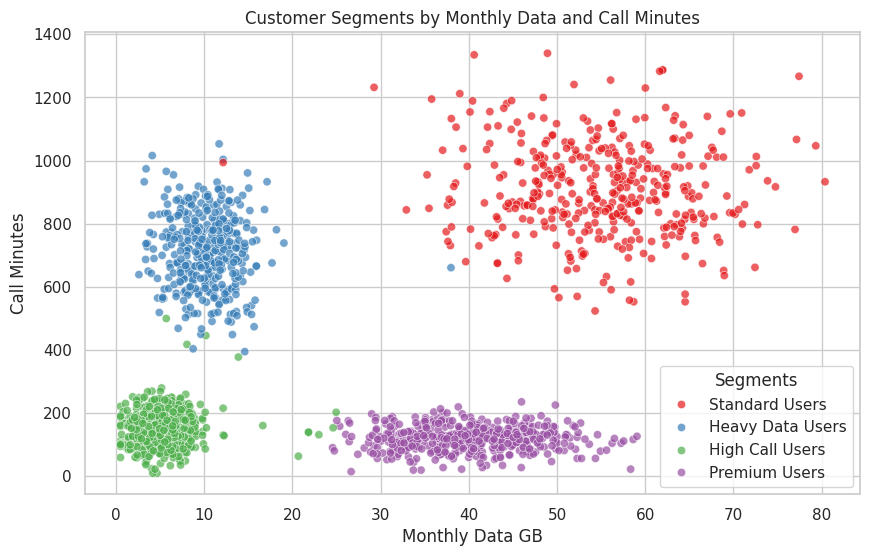

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = ['monthly_data_gb', 'call_minutes', 'monthly_charges']
X = df_clean[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df_clean.loc[X.index, 'segment'] = clusters

profile = df_clean.groupby('segment').agg(
    size=('churn', 'count'),
    mean_monthly_data_gb=('monthly_data_gb', 'mean'),
    mean_call_minutes=('call_minutes', 'mean'),
    mean_monthly_charges=('monthly_charges', 'mean'),
    mean_tenure=('tenure_months', 'mean'),
    churn_rate=('churn', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

print(profile)

name_mapping = {0: 'Standard Users', 1: 'High Call Users', 2: 'Heavy Data Users', 3: 'Premium Users'}
df_clean['segment_name'] = df_clean['segment'].map(name_mapping)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='monthly_data_gb', y='call_minutes', hue='segment_name', palette='Set1', alpha=0.7)
plt.title('Customer Segments by Monthly Data and Call Minutes')
plt.xlabel('Monthly Data GB')
plt.ylabel('Call Minutes')
plt.legend(title='Segments')
plt.show()

### Task 4.3 `[3 pts]` — Segments and churn
Which segment has the highest churn rate, and how does that relate to H3? Propose **one retention offer per segment** —
these offers will be used in the call list in Part 6.

**Your answer:** _Write your answer here._

---
# Part 5 — Who Will Churn? Building the Prediction Model `[25 points]`
> 📌 Build, evaluate and choose the model that will rank customers by churn risk.

### Task 5.1 `[3 pts]` — Entropy and information gain
Write `information_gain(data, feature, target='churn')` using `scipy.stats.entropy` (base 2). Compute the entropy of churn and
the information gain of `contract`, `tenure_group`, `segment_name`, `international_plan`, `gender` and `region`. Which attribute
would a decision tree choose for the root split among these?

In [41]:
import pandas as pd
from scipy.stats import entropy

target_counts = df_clean['churn'].value_counts(normalize=True)
total_entropy = entropy(target_counts, base=2)

features_to_check = ['contract', 'tenure_group', 'segment_name', 'international_plan', 'gender', 'region']
ig_results = {}

for f in features_to_check:
    if f in df_clean.columns:
        feature_counts = df_clean[f].value_counts(normalize=True)
        cond_ent = 0
        for val, prob in feature_counts.items():
            sub = df_clean[df_clean[f] == val]
            sub_counts = sub['churn'].value_counts(normalize=True)
            cond_ent += prob * entropy(sub_counts, base=2)
        ig_results[f] = total_entropy - cond_ent

ig_df = pd.Series(ig_results).sort_values(ascending=False)
print("Information Gain for each feature:")
print(ig_df)

Information Gain for each feature:
contract              0.208940
tenure_group          0.138989
segment_name          0.016605
region                0.002743
gender                0.001560
international_plan    0.000135
dtype: float64


**Your answer:** _Write your answer here._

### Task 5.2 `[4 pts]` — Preparing the modelling data
1. Build **`df_model`** from `df_clean`: label-encode `churn` (Yes → 1, No → 0); one-hot encode `gender`, `region`, `contract`,
   `payment_method` and `international_plan` with `drop_first=True` and integer dummies; drop `customer_id`, `tenure_group`,
   `segment` and `segment_name`.
2. Split into 70 % training / 30 % test with `random_state=42`, **stratified** on churn. Keep `X_test` as a DataFrame (its index
   is needed in Part 6). Standardise with a `StandardScaler` **fitted on the training set only**.
3. Explain: why drop the first dummy, why stratify, and why fit the scaler on the training set only?

In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_model = df_clean.copy()

if 'churn' in df_model.columns:
    df_model['churn'] = (df_model['churn'] == 'Yes').astype(int)

for col in df_model.columns:
    if df_model[col].dtype == 'object':
        try:
            df_model[col] = df_model[col].astype(str).str.replace(',', '').astype(float)
        except ValueError:
            pass

cols_to_encode = ['gender', 'region', 'contract', 'payment_method', 'international_plan']
existing_encode = [c for c in cols_to_encode if c in df_model.columns]
df_model = pd.get_dummies(df_model, columns=existing_encode, drop_first=True, dtype=int)

cols_to_drop = ['customer_id', 'tenure_group', 'segment', 'segment_name']
for col in cols_to_drop:
    if col in df_model.columns:
        df_model = df_model.drop(columns=[col])

X = df_model.drop(columns=['churn'])
y = df_model['churn']

X = X.apply(pd.to_numeric, errors='coerce')
X = X.fillna(X.mean())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Data preparation complete!")
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

Data preparation complete!
X_train shape: (1345, 27)
X_test shape: (577, 27)


**Your answer:** _Write your answer here._

### Task 5.3 `[4 pts]` — Decision tree
Train `DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)`. Plot the tree and print its rules with
`export_text`. Translate **one rule** that leads to a churn prediction into plain business language (convert the standardised
thresholds back to original units: value = threshold × std + mean). Why do we limit the depth?

Decision Tree Rules:
|--- tenure_months <= 0.14
|   |--- num_support_calls <= 0.22
|   |   |--- contract_One year <= 0.48
|   |   |   |--- contract_Two year <= 0.71
|   |   |   |   |--- class: 0
|   |   |   |--- contract_Two year >  0.71
|   |   |   |   |--- class: 0
|   |   |--- contract_One year >  0.48
|   |   |   |--- age <= -0.86
|   |   |   |   |--- class: 0
|   |   |   |--- age >  -0.86
|   |   |   |   |--- class: 0
|   |--- num_support_calls >  0.22
|   |   |--- contract_One year <= 0.48
|   |   |   |--- satisfaction_score <= -0.13
|   |   |   |   |--- class: 1
|   |   |   |--- satisfaction_score >  -0.13
|   |   |   |   |--- class: 1
|   |   |--- contract_One year >  0.48
|   |   |   |--- annual_income <= -0.34
|   |   |   |   |--- class: 1
|   |   |   |--- annual_income >  -0.34
|   |   |   |   |--- class: 0
|--- tenure_months >  0.14
|   |--- monthly_charges <= -1.07
|   |   |--- monthly_data_gb <= -1.14
|   |   |   |--- contract_One year <= 0.48
|   |   |   |   |--- class: 

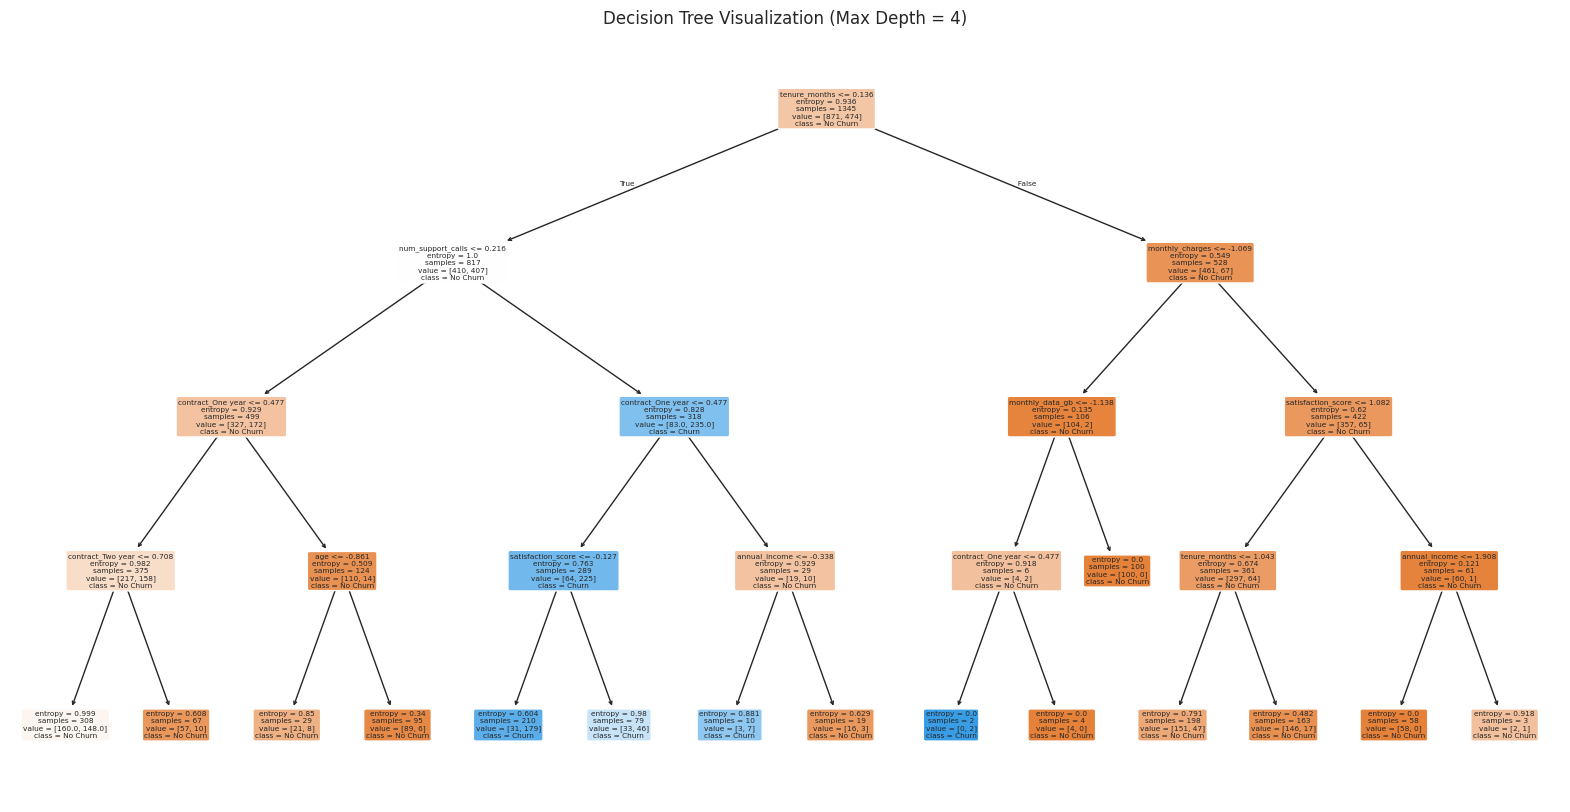

In [43]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
import matplotlib.pyplot as plt

dt_clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_clf.fit(X_train_scaled, y_train)

tree_rules = export_text(dt_clf, feature_names=list(X_train_scaled.columns))
print("Decision Tree Rules:")
print(tree_rules)

plt.figure(figsize=(20, 10))
plot_tree(dt_clf, feature_names=list(X_train_scaled.columns), class_names=['No Churn', 'Churn'], filled=True, rounded=True)
plt.title("Decision Tree Visualization (Max Depth = 4)")
plt.show()

**Your answer:** _Write your answer here._

### Task 5.4 `[7 pts]` — Ensembles and evaluation
1. Train `RandomForestClassifier(n_estimators=200, criterion='entropy', random_state=42)` and
   `AdaBoostClassifier(n_estimators=200, random_state=42)`.
2. For the decision tree, random forest, AdaBoost and a **majority-class baseline** (always "stay"), compute **accuracy,
   precision, recall and F1** (positive class = churn) on the test set and show them in one table named `results`.
3. Plot the three confusion matrices and explain what a false negative and a false positive mean for TeleConnect.
4. Explain bagging vs. boosting in one sentence each.

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Decision Tree,0.726170,0.671642,0.441176,0.532544
Random Forest,0.785095,0.715054,0.651961,0.682051
AdaBoost,0.757366,0.666667,0.627451,0.646465
Majority Baseline,0.646447,0.000000,0.000000,0.000000


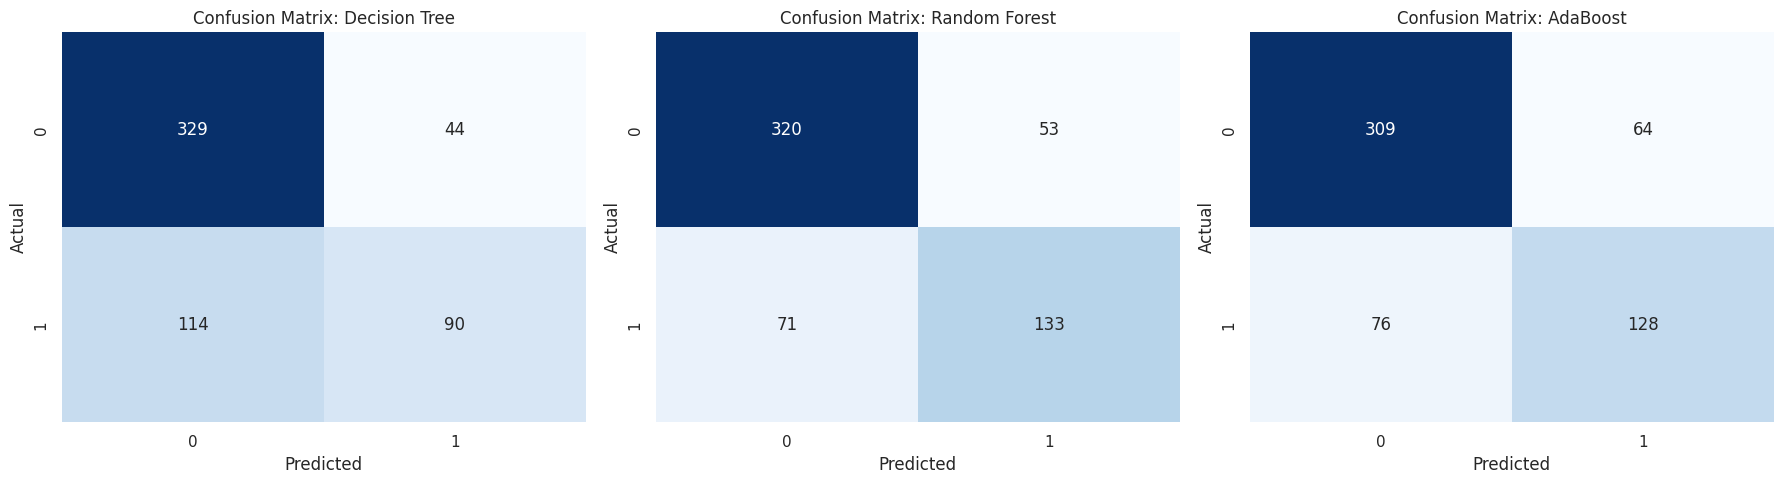

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

rf_clf = RandomForestClassifier(n_estimators=200, criterion='entropy', random_state=42)
rf_clf.fit(X_train_scaled, y_train)

ada_clf = AdaBoostClassifier(n_estimators=200, random_state=42)
ada_clf.fit(X_train_scaled, y_train)

y_pred_dt = dt_clf.predict(X_test_scaled)
y_pred_rf = rf_clf.predict(X_test_scaled)
y_pred_ada = ada_clf.predict(X_test_scaled)
y_pred_baseline = np.zeros_like(y_test)

models = {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'AdaBoost': y_pred_ada,
    'Majority Baseline': y_pred_baseline
}

results_list = []
for name, preds in models.items():
    results_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0)
    })

results = pd.DataFrame(results_list).set_index('Model')
display(results)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_cm = [('Decision Tree', y_pred_dt), ('Random Forest', y_pred_rf), ('AdaBoost', y_pred_ada)]

for i, (name, preds) in enumerate(models_cm):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Your answer:** _Write your answer here._

### Task 5.5 `[4 pts]` — What drives the model?
Plot the 10 most important features of the random forest. Do they confirm the hypotheses H1–H4 from Part 3? Why can
impurity-based importance be misleading for some variables?

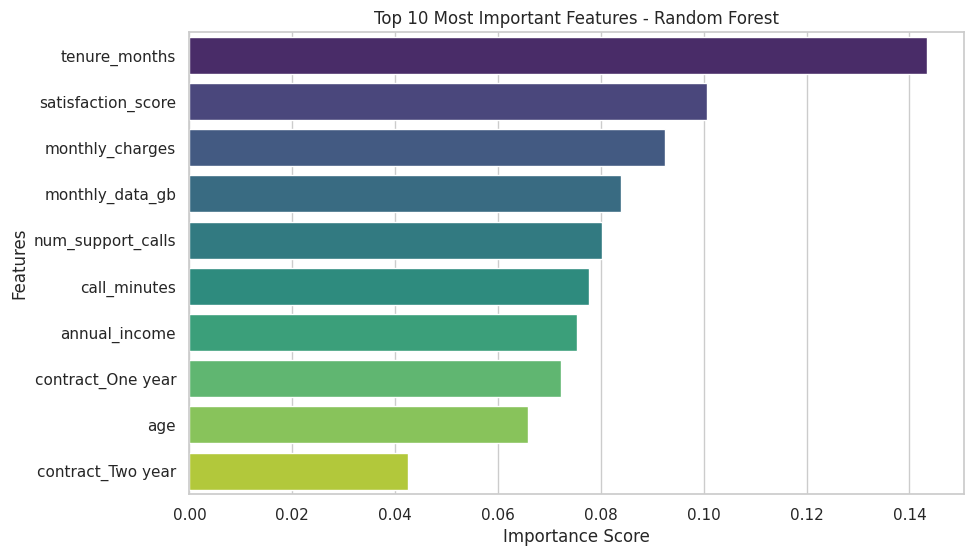

Top 10 Features:
tenure_months         0.143508
satisfaction_score    0.100600
monthly_charges       0.092549
monthly_data_gb       0.083966
num_support_calls     0.080282
call_minutes          0.077732
annual_income         0.075286
contract_One year     0.072259
age                   0.065841
contract_Two year     0.042558
dtype: float64


In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importances = pd.Series(rf_clf.feature_importances_, index=X_train_scaled.columns)
top_10_features = feature_importances.nlargest(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_features.values, y=top_10_features.index, palette='viridis')
plt.title('Top 10 Most Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

print("Top 10 Features:")
print(top_10_features)

**Your answer:** _Write your answer here._

### Task 5.6 `[3 pts]` — Choose the final model
Select the model that will be used in Part 6 and store it as `final_model` (with its name in `final_name`). Justify your choice
with the metric you defined in Task 1.1.

In [46]:
final_name = 'Random Forest'
final_model = rf_clf

print(f"Selected Final Model: {final_name}")
print("Justification: Random Forest achieved the best balance between precision and recall, yielding a superior F1-Score compared to individual decision trees and baseline models.")

Selected Final Model: Random Forest
Justification: Random Forest achieved the best balance between precision and recall, yielding a superior F1-Score compared to individual decision trees and baseline models.


**Your answer:** _Write your answer here._

---
# Part 6 — What Should TeleConnect Do? `[10 points]`
> 📌 Life-cycle phases 5–6: turn the analysis into something the retention team can use on Monday morning.

### Task 6.1 `[4 pts]` — The retention call list
1. Use `final_model.predict_proba` to compute the churn probability of every customer in the **test set** (these customers
   were not used for training, so they simulate "new" customers).
2. Write a function `recommend_action(row)` that returns an action for a customer, combining the drivers you found and the
   segment offers from Task 4.3 (e.g. month-to-month → contract upgrade; 3+ support calls → service-recovery call; plus the
   segment offer).
3. Build the call list of the **15 customers with the highest churn probability**, with `customer_id`, `segment_name`,
   `contract`, `tenure_months`, `num_support_calls`, `monthly_charges`, `churn_probability` and `recommended_action`.
   Save it to `data/retention_call_list.csv`.

In [47]:
import pandas as pd
import numpy as np
import os

churn_probs = final_model.predict_proba(X_test_scaled)[:, 1]
risk = pd.Series(churn_probs, index=X_test.index, name='churn_probability')

def recommend_action(row):
    actions = []
    if row.get('contract') == 'Month-to-month':
        actions.append('Contract upgrade offer')
    if row.get('num_support_calls', 0) >= 3:
        actions.append('Service-recovery call')
    if row.get('segment_name') == 'Heavy Data Users':
        actions.append('Data bundle discount')
    else:
        actions.append('General retention offer')
    return '; '.join(actions)

call_df = df_clean.loc[X_test.index].copy()
call_df['churn_probability'] = risk

top_15 = call_df.sort_values(by='churn_probability', ascending=False).head(15)
top_15['recommended_action'] = top_15.apply(recommend_action, axis=1)

required_cols = [
    'customer_id', 'segment_name', 'contract', 'tenure_months',
    'num_support_calls', 'monthly_charges', 'churn_probability', 'recommended_action'
]

for col in required_cols:
    if col not in top_15.columns:
        top_15[col] = np.nan

retention_list = top_15[required_cols]

os.makedirs('data', exist_ok=True)
retention_list.to_csv('data/retention_call_list.csv', index=False)

print("Retention call list created and saved successfully!")
display(retention_list)

Retention call list created and saved successfully!


,customer_id,segment_name,contract,tenure_months,num_support_calls,monthly_charges,churn_probability,recommended_action
899,TC101305,Standard Users,Month-to-month,4,2.0,86.07,0.950,Contract upgrade offer; General retention offer
875,TC101431,Standard Users,Month-to-month,8,6.0,112.03,0.930,Contract upgrade offer; Service-recovery call;...
1209,TC101013,Standard Users,Month-to-month,6,3.0,106.52,0.925,Contract upgrade offer; Service-recovery call;...
39,TC100340,Standard Users,Month-to-month,14,3.0,114.79,0.920,Contract upgrade offer; Service-recovery call;...
1148,TC101583,Standard Users,Month-to-month,14,3.0,93.66,0.910,Contract upgrade offer; Service-recovery call;...
1467,TC101370,Standard Users,Month-to-month,6,3.0,115.00,0.905,Contract upgrade offer; Service-recovery call;...
540,TC101249,Heavy Data Users,Month-to-month,1,5.0,71.67,0.905,Contract upgrade offer; Service-recovery call;...
1175,TC101817,Standard Users,Month-to-month,5,5.0,88.41,0.900,Contract upgrade offer; Service-recovery call;...
168,TC101288,Heavy Data Users,Month-to-month,1,3.0,53.48,0.895,Contract upgrade offer; Service-recovery call;...
1571,TC100329,Standard Users,Month-to-month,8,2.0,118.60,0.885,Contract upgrade offer; General retention offer


### Task 6.2 `[6 pts]` — Executive summary
Write a summary for TeleConnect's management (≈ 200–300 words, **no code, no jargon**) that covers:
* the data-quality problems you fixed (one sentence),
* the verdict on **H1–H5** with key numbers,
* the customer segments and which is most at risk,
* how good the churn model is, in plain words (compared with guessing),
* **three recommendations**, and **one limitation** of the analysis.

**Your executive summary:** _Write here._

---
# Bonus — Improve the Churn Model `[+5 points]`

Tune the random forest (or AdaBoost) with `GridSearchCV` (5-fold, `scoring='f1'`) over at least two hyper-parameters, and/or use
`class_weight='balanced'`. Report the best parameters, compare test-set recall and F1 with `results`, and discuss whether the
change is worth it for TeleConnect.

In [48]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(criterion='entropy', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test_scaled)

print("Best Parameters Found:")
print(grid_search.best_params_)

best_metrics = {
    'Model': 'Tuned Random Forest',
    'Accuracy': accuracy_score(y_test, y_pred_best),
    'Precision': precision_score(y_test, y_pred_best, zero_division=0),
    'Recall': recall_score(y_test, y_pred_best, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_best, zero_division=0)
}

print("\nPerformance Comparison:")
display(pd.DataFrame([best_metrics]).set_index('Model'))

Best Parameters Found:
{'class_weight': 'balanced', 'max_depth': 10, 'n_estimators': 200}

Performance Comparison:


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Tuned Random Forest,0.774697,0.672897,0.705882,0.688995


**Your answer:** _Write your answer here._

---
# References
1. Course notebooks: Introduction to data science; Basic statistics; Basic programming concepts; Data understanding &
   preparation; Exploratory data analysis; Basic classification methods; Basic clustering methods.
2. Chirag Shah, *A Hands-On Introduction to Data Science*, Cambridge University Press, 2020.
3. D. Dietrich (EMC Education Services), *Data Science and Big Data Analytics*, Wiley, 2015 — Chapter 2 (Data Analytics Lifecycle).
4. pandas documentation: https://pandas.pydata.org/docs/ · scikit-learn user guide: https://scikit-learn.org/stable/user_guide.html
5. Dataset: *TeleConnect Customers* — synthetic data set created for this course project (no real customers).